# PFAS comparison 1 — XGBoost replacement: Physics-informed Bayesian Ridge
 Google Colab notebook | grouped 5-fold CV + Bayesian optimisation + uncertainty + SHAP

## 1. Install and import




In [1]:
%pip -q install optuna shap openpyxl

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 442.4/442.4 kB 8.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.7/268.7 kB 12.5 MB/s eta 0:00:00


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import optuna
import shap
import joblib
from sklearn.model_selection import GroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import BayesianRidge
from sklearn.metrics import mean_squared_error, mean_absolute_error

optuna.logging.set_verbosity(optuna.logging.WARNING)
np.random.seed(42)

## 2. Load Excel dataset

In [3]:
from google.colab import files
uploaded = files.upload()
file_name = list(uploaded.keys())[0]
df = pd.read_excel(file_name, sheet_name='data')
df.head()

Saving AFFF_data_final_20240308.xlsx to AFFF_data_final_20240308.xlsx


,Membrane,MWCO (Da),Isoelectric point,Water contact angle,PFAS,Mw,SMILES,Compound size (Å),log Kow,pKa,Initial concentration (ng/L),IS (mM),Pressure (psi),pH,Removal_rate,ref_ID,ref
0,NF90,118,3.28,52.9,PFBA,214,C(=O)(C(C(C(F)(F)F)(F)F)(F)F)[O-],3.628016,-1.22,0.37,287.925,10.0,185.0,7.0,81.961093,1,exp
1,NF90,118,3.28,52.9,PFPeA,264,C(=O)(C(C(C(C(F)(F)F)(F)F)(F)F)(F)F)[O-],4.015968,-0.52,0.34,513.900,10.0,185.0,7.0,89.863274,1,exp
2,NF90,118,3.28,52.9,PFBS,300,C(C(C(F)(F)S(=O)(=O)[O-])(F)F)(C(F)(F)F)(F)F,3.992443,0.25,-3.31,4247.025,10.0,185.0,7.0,98.819583,1,exp
3,NF90,118,3.28,52.9,PFHxA,314,C(=O)(C(C(C(C(C(F)(F)F)(F)F)(F)F)(F)F)(F)F)[O-],4.128813,0.18,0.32,2275.425,10.0,185.0,7.0,98.270808,1,exp
4,NF90,118,3.28,52.9,PFPeS,350,C(C(C(F)(F)F)(F)F)(C(C(F)(F)S(=O)(=O)[O-])(F)F...,4.317291,0.95,-3.32,3333.175,10.0,185.0,7.0,98.560089,1,exp


## 3. Preprocess the experimental variables

In [4]:
df = df.rename(columns={
    'MWCO (Da)': 'MWCO',
    'Isoelectric point': 'IEP',
    'Water contact angle': 'CA',
    'Compound size (Å)': 'Size',
    'Initial concentration (ng/L)': 'Init_conc',
    'IS (mM)': 'IS',
    'Pressure (psi)': 'Pres'
})

df['ref_ID'] = df['ref_ID'].astype(str)
df['charge'] = -1 / (1 + 10 ** np.clip(df['pKa'] - df['pH'], -100, 100))
df['charge_product'] = (df['IEP'] - df['pH']) * df['charge']
df['Init_conc'] = df['Init_conc'] / df['Mw']
df['log_conc'] = np.log10(df['Init_conc'].clip(lower=1e-8))
df['MWCO_log'] = np.log1p(df['MWCO'])
df['pressure_log'] = np.log1p(df['Pres'])
df['Mw_by_MWCO'] = df['Mw'] / df['MWCO']
df['molecular_size_ratio'] = df['Size'] / np.sqrt(df['MWCO'])

train = df[df['ref_ID'] != '1'].copy()
test = df[df['ref_ID'] == '1'].copy()
train['group'] = train['ref_ID'] + '_' + train['PFAS']

print('Training observations:', len(train))
print('Experimental test observations:', len(test))

Training observations: 457
Experimental test observations: 77


## 4. Select features and create grouped CV


In [5]:
features = [
    'MWCO', 'CA', 'Size', 'log Kow', 'log_conc',
    'Pres', 'IS', 'charge_product', 'IEP', 'pH',
    'pKa', 'Mw', 'MWCO_log', 'pressure_log',
    'Mw_by_MWCO', 'molecular_size_ratio'
]

X_train = train[features]
y_train = train['Removal_rate']
X_test = test[features]
y_test = test['Removal_rate']
groups = train['group']

cv = GroupKFold(n_splits=5)
folds = list(cv.split(X_train, y_train, groups))

## 5. Grouped 5-fold CV + Bayesian hyperparameter search


In [6]:
N_TRIALS = 15

def make_model(params):
    return make_pipeline(
        StandardScaler(),
        BayesianRidge(
            alpha_1=params['alpha_1'],
            alpha_2=params['alpha_2'],
            lambda_1=params['lambda_1'],
            lambda_2=params['lambda_2']
        )
    )

def objective(trial):
    params = {
        'alpha_1': trial.suggest_float('alpha_1', 1e-9, 1e-3, log=True),
        'alpha_2': trial.suggest_float('alpha_2', 1e-9, 1e-3, log=True),
        'lambda_1': trial.suggest_float('lambda_1', 1e-9, 1e-3, log=True),
        'lambda_2': trial.suggest_float('lambda_2', 1e-9, 1e-3, log=True)
    }
    predictions = np.zeros(len(train))
    for train_ids, val_ids in folds:
        model = make_model(params)
        model.fit(X_train.iloc[train_ids], y_train.iloc[train_ids])
        predictions[val_ids] = model.predict(X_train.iloc[val_ids])
    return np.sqrt(mean_squared_error(y_train, predictions))

study = optuna.create_study(direction='minimize', sampler=optuna.samplers.TPESampler(seed=42))
study.optimize(objective, n_trials=N_TRIALS)

print('Best grouped CV RMSE:', round(study.best_value, 3))
print('Best hyperparameters:', study.best_params)

Best grouped CV RMSE: 8.548
Best hyperparameters: {'alpha_1': 1.1121853473062499e-07, 'alpha_2': 1.015907003477362e-05, 'lambda_1': 0.0009373661684574769, 'lambda_2': 1.0706787630075477e-05}


## 6. Train on all 457 observations, then evaluate the 77 test observations once in this run

In [7]:
model = make_model(study.best_params)
model.fit(X_train, y_train)

train_pred = np.clip(model.predict(X_train), 0, 100)
test_pred = np.clip(model.predict(X_test), 0, 100)

train_rmse = np.sqrt(mean_squared_error(y_train, train_pred))
train_mae = mean_absolute_error(y_train, train_pred)
test_rmse = np.sqrt(mean_squared_error(y_test, test_pred))
test_mae = mean_absolute_error(y_test, test_pred)

results = pd.DataFrame({
    'Model': ['XGBoost (published)', 'Bayesian Ridge (new)'],
    'Test RMSE (%)': [8.4, test_rmse],
    'Test MAE (%)': [6.4, test_mae],
    'Source': ['Original paper', 'This notebook']
})

print('Training RMSE:', round(train_rmse, 3))
print('Training MAE:', round(train_mae, 3))
print('External test RMSE:', round(test_rmse, 3))
print('External test MAE:', round(test_mae, 3))
display(results)

Training RMSE: 6.466
Training MAE: 4.431
External test RMSE: 7.158
External test MAE: 5.473


,Model,Test RMSE (%),Test MAE (%),Source
0,XGBoost (published),8.40000,6.400000,Original paper
1,Bayesian Ridge (new),7.15776,5.472818,This notebook


## 7. Uncertainty (Bayesian predictive standard deviation)

Observed 95% interval coverage: 93.5 %


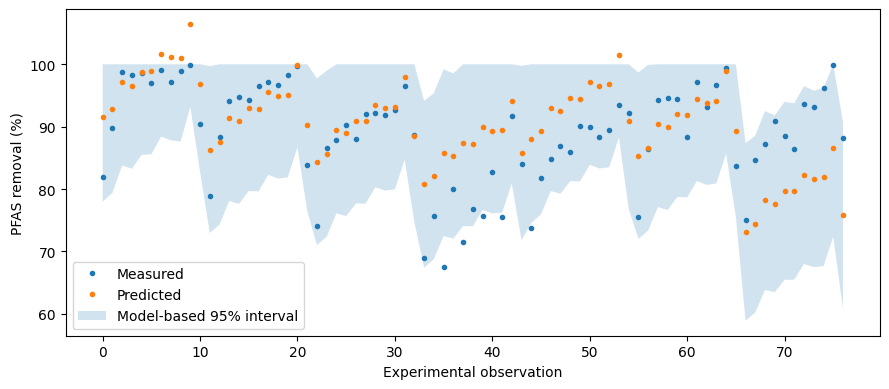

In [8]:
scaled_test = model.named_steps['standardscaler'].transform(X_test)
mean, std = model.named_steps['bayesianridge'].predict(scaled_test, return_std=True)
lower = np.clip(mean - 1.96 * std, 0, 100)
upper = np.clip(mean + 1.96 * std, 0, 100)
coverage = np.mean((y_test >= lower) & (y_test <= upper)) * 100
print('Observed 95% interval coverage:', round(coverage, 1), '%')

plt.figure(figsize=(9, 4))
plt.plot(y_test.to_numpy(), '.', label='Measured')
plt.plot(mean, '.', label='Predicted')
plt.fill_between(np.arange(len(test)), lower, upper, alpha=0.2, label='Model-based 95% interval')
plt.xlabel('Experimental observation')
plt.ylabel('PFAS removal (%)')
plt.legend()
plt.tight_layout()
plt.savefig('bayesian_intervals.png', dpi=200)
plt.show()

## 8. SHAP explanation of the Bayesian Ridge model

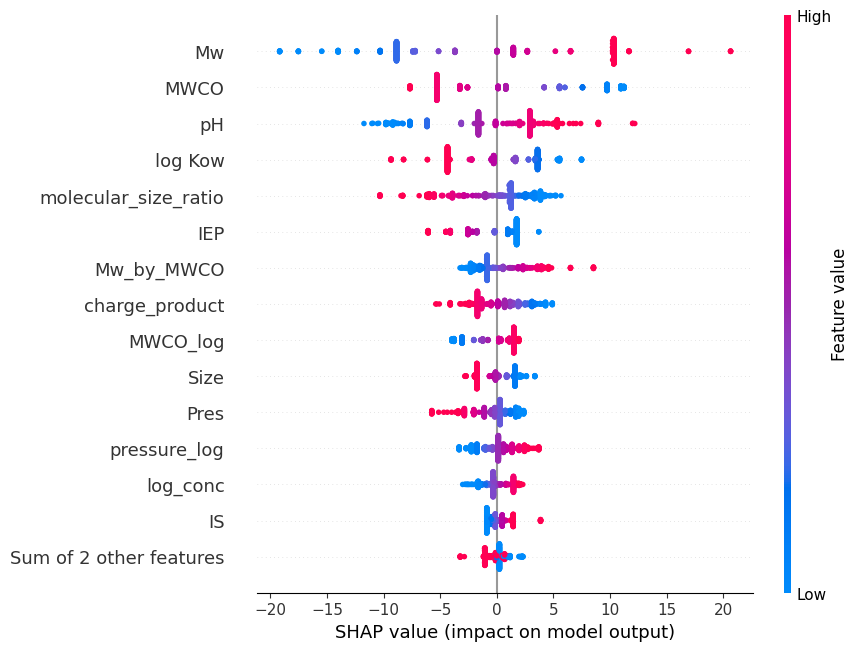

In [9]:
scaled_train = model.named_steps['standardscaler'].transform(X_train)
explainer = shap.Explainer(model.named_steps['bayesianridge'], scaled_train, feature_names=features)
shap_values = explainer(scaled_train)
shap.plots.beeswarm(shap_values, max_display=15, show=True)

## 9. Predictions and exports

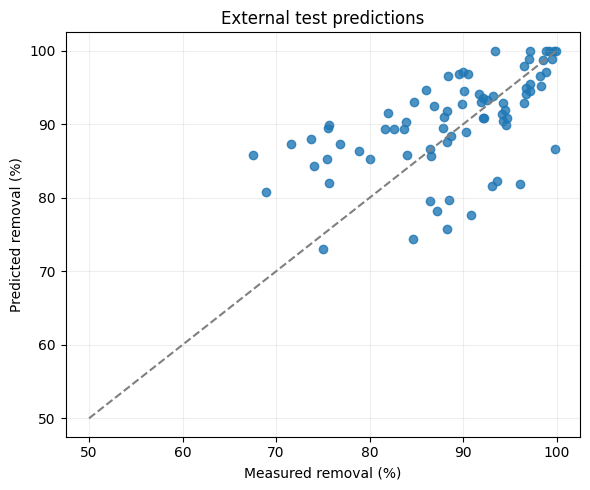

In [10]:
plt.figure(figsize=(6, 5))
plt.scatter(y_test, test_pred, alpha=0.8)
plt.plot([50, 100], [50, 100], '--', color='gray')
plt.xlabel('Measured removal (%)')
plt.ylabel('Predicted removal (%)')
plt.title('External test predictions')
plt.grid(alpha=0.2)
plt.tight_layout()
plt.savefig('test_predictions.png', dpi=200)
plt.show()

## 10. Molecular–membrane reliability analysis



,Model,PFAS,Membrane,n,RMSE (pp),MAE (pp),Bias (pp),Small group
0,Bayesian Ridge,FOSA,NF,1,6.470,6.470,6.470,True
1,Bayesian Ridge,FOSA,NF270,3,1.327,1.151,0.054,False
2,Bayesian Ridge,FOSA,NF270-PAA,1,5.598,5.598,5.598,True
3,Bayesian Ridge,FOSA,NF270-PEI,1,12.465,12.465,-12.465,True
4,Bayesian Ridge,FOSA,NF90,1,6.310,6.310,6.310,True
5,Bayesian Ridge,PFBA,NF,1,7.451,7.451,7.451,True
6,Bayesian Ridge,PFBA,NF270,3,12.241,12.134,12.134,False
7,Bayesian Ridge,PFBA,NF270-PAA,1,9.855,9.855,9.855,True
8,Bayesian Ridge,PFBA,NF270-PEI,1,1.968,1.968,-1.968,True
9,Bayesian Ridge,PFBA,NF90,1,9.510,9.510,9.510,True


,Model,n,RMSE (pp),MAE (pp),Bias (pp),Equal-pair RMSE (pp),Equal-pair MAE (pp),Observed pairs
0,Bayesian Ridge,77,7.158,5.473,1.391,6.755,5.121,55


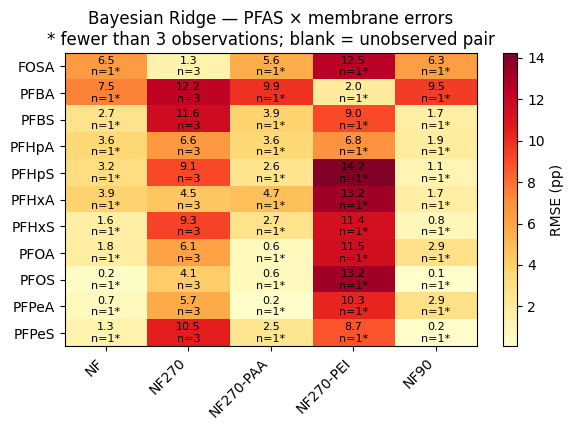

In [11]:
from pathlib import Path
import json as nv_json
import hashlib as nv_hashlib
import shutil as nv_shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.preprocessing import StandardScaler as NVScaler
from sklearn.neighbors import NearestNeighbors as NVNeighbors

nv_train=train.copy().reset_index(drop=True)
nv_test=test.copy().reset_index(drop=True)
nv_y=nv_test['Removal_rate'].to_numpy(dtype=float)
nv_primary='Bayesian Ridge'
nv_predictions={nv_primary:np.asarray(test_pred,dtype=float).ravel().copy()}
nv_dir=Path('ridge_novelty_results');nv_dir.mkdir(exist_ok=True)
nv_min_n=3
for nv_name,nv_pred in nv_predictions.items():
 assert len(nv_pred)==len(nv_test) and np.isfinite(nv_pred).all(),nv_name
assert np.allclose(nv_y,np.asarray(y_test).ravel())

def nv_plot(fig,name):
 fig.tight_layout()
 for ext in ['png','pdf']:fig.savefig(nv_dir/f'{name}.{ext}',dpi=250,bbox_inches='tight')
 plt.show();plt.close(fig)

def nv_errors(y,p):
 return {'n':len(y),'RMSE (pp)':float(np.sqrt(np.mean((p-y)**2))),
         'MAE (pp)':float(np.mean(np.abs(p-y))), 'Bias (pp)':float(np.mean(p-y))}

nv_rows=[]
for nv_name,nv_pred in nv_predictions.items():
 for (nv_pfas,nv_mem),nv_idx in nv_test.groupby(['PFAS','Membrane']).groups.items():
  nv_idx=np.array(list(nv_idx))
  nv_rows.append({'Model':nv_name,'PFAS':nv_pfas,'Membrane':nv_mem,
   **nv_errors(nv_y[nv_idx],nv_pred[nv_idx])})
nv_pairs=pd.DataFrame(nv_rows)
nv_pairs['Small group']=nv_pairs['n']<nv_min_n
nv_pairs.to_csv(nv_dir/'molecule_membrane_errors.csv',index=False)
display(nv_pairs.round(3))
# Equal pair weighting prevents frequently measured pairs dominating every metric.
nv_balance=[]
for nv_name,nv_pred in nv_predictions.items():
 nv_g=nv_pairs[nv_pairs.Model==nv_name]
 nv_balance.append({'Model':nv_name,**nv_errors(nv_y,nv_pred),
  'Equal-pair RMSE (pp)':np.sqrt(np.mean(nv_g['RMSE (pp)']**2)),
  'Equal-pair MAE (pp)':nv_g['MAE (pp)'].mean(),'Observed pairs':len(nv_g)})
nv_balance=pd.DataFrame(nv_balance)
nv_balance.to_csv(nv_dir/'sample_vs_pair_weighting.csv',index=False);display(nv_balance.round(3))

nv_map=nv_pairs[nv_pairs.Model==nv_primary]
nv_grid=nv_map.pivot(index='PFAS',columns='Membrane',values='RMSE (pp)')
nv_counts=nv_map.pivot(index='PFAS',columns='Membrane',values='n').reindex_like(nv_grid)
nv_fig,nv_ax=plt.subplots(figsize=(max(6,.9*len(nv_grid.columns)),max(4,.4*len(nv_grid))))
nv_im=nv_ax.imshow(np.ma.masked_invalid(nv_grid.to_numpy()),aspect='auto',cmap='YlOrRd')
nv_ax.set_xticks(range(len(nv_grid.columns)),nv_grid.columns,rotation=45,ha='right')
nv_ax.set_yticks(range(len(nv_grid.index)),nv_grid.index)
for nv_i in range(len(nv_grid)):
 for nv_j in range(len(nv_grid.columns)):
  if np.isfinite(nv_grid.iloc[nv_i,nv_j]):
   nv_n=int(nv_counts.iloc[nv_i,nv_j]);nv_mark='*' if nv_n<nv_min_n else ''
   nv_ax.text(nv_j,nv_i,f'{nv_grid.iloc[nv_i,nv_j]:.1f}\nn={nv_n}{nv_mark}',ha='center',va='center',fontsize=8)
nv_fig.colorbar(nv_im,ax=nv_ax,label='RMSE (pp)')
nv_ax.set_title(nv_primary+' — PFAS × membrane errors\n* fewer than 3 observations; blank = unobserved pair')
nv_plot(nv_fig,'molecule_membrane_error_map')


## 11. Physical regimes and distance from training conditions




,Stratification,Regime,Model,n,RMSE (pp),MAE (pp),Bias (pp),Small group
0,Size regime × Charge magnitude,"('Above training median', 'Above training medi...",Bayesian Ridge,15,3.673,2.596,1.635,False
1,Size regime × Charge magnitude,"('Above training median', 'At/below training m...",Bayesian Ridge,3,11.115,10.673,-6.467,False
2,Size regime × Charge magnitude,"('At/below training median', 'Above training m...",Bayesian Ridge,39,5.231,4.007,2.109,False
3,Size regime × Charge magnitude,"('At/below training median', 'At/below trainin...",Bayesian Ridge,20,10.735,9.708,0.989,False
4,Charge sign,Negative,Bayesian Ridge,11,10.804,10.263,-10.263,False
5,Charge sign,Positive,Bayesian Ridge,66,6.350,4.674,3.334,False
6,Support,Within distance threshold,Bayesian Ridge,77,7.158,5.473,1.391,False
7,Unseen PFAS,False,Bayesian Ridge,77,7.158,5.473,1.391,False
8,Unseen membrane,False,Bayesian Ridge,44,7.247,5.427,5.040,False
9,Unseen membrane,True,Bayesian Ridge,33,7.037,5.534,-3.473,False


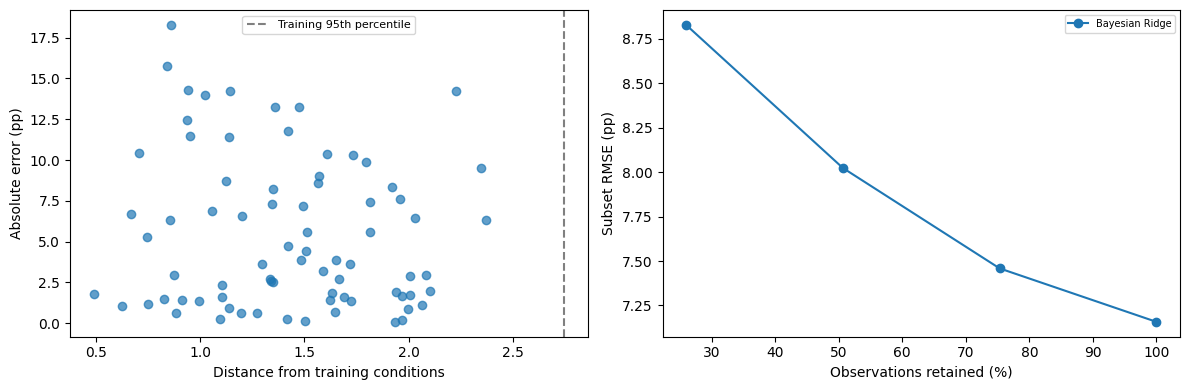

In [12]:
def nv_physical(frame):
 z=frame[['MWCO','CA','Size','log Kow','Init_conc','Pres','IS','charge_product']].astype(float).copy()
 z['Init_conc']=np.log10(z.Init_conc.clip(lower=1e-8))
 return z
nv_sc=NVScaler().fit(nv_physical(nv_train))
nv_z=nv_sc.transform(nv_physical(nv_train));nv_t=nv_sc.transform(nv_physical(nv_test))
nv_group=nv_train.ref_ID.astype(str)+'|'+nv_train.PFAS.astype(str)
nv_refdist=np.empty(len(nv_train))
for nv_g in nv_group.unique():
 nv_hold=(nv_group==nv_g).to_numpy();nv_k=min(5,int((~nv_hold).sum()))
 if nv_k<1:raise ValueError('Need at least two training reference–PFAS groups.')
 nv_nn=NVNeighbors(n_neighbors=nv_k).fit(nv_z[~nv_hold])
 nv_refdist[nv_hold]=nv_nn.kneighbors(nv_z[nv_hold])[0].mean(axis=1)
nv_nn=NVNeighbors(n_neighbors=min(5,len(nv_train))).fit(nv_z)
nv_distance=nv_nn.kneighbors(nv_t)[0].mean(axis=1)
nv_threshold=float(np.quantile(nv_refdist,.95))
nv_ratio_cut=float(np.median(nv_train.Mw/nv_train.MWCO))
nv_charge_cut=float(np.median(np.abs(nv_train.charge_product)))
nv_audit=nv_test[['ref_ID','PFAS','Membrane']].copy()
nv_audit['MW/MWCO']=nv_test.Mw/nv_test.MWCO
nv_audit['Size regime']=np.where(nv_audit['MW/MWCO']>nv_ratio_cut,'Above training median','At/below training median')
nv_audit['Charge magnitude']=np.where(np.abs(nv_test.charge_product)>nv_charge_cut,'Above training median','At/below training median')
nv_audit['Charge sign']=np.where(nv_test.charge_product>0,'Positive',np.where(nv_test.charge_product<0,'Negative','Zero'))
nv_audit['Distance']=nv_distance
nv_audit['Support']=np.where(nv_distance<=nv_threshold,'Within distance threshold','Beyond distance threshold')
nv_audit['Unseen PFAS']=~nv_test.PFAS.isin(nv_train.PFAS)
nv_audit['Unseen membrane']=~nv_test.Membrane.isin(nv_train.Membrane)
nv_regime=[]
for nv_keys in [['Size regime','Charge magnitude'],['Charge sign'],['Support'],['Unseen PFAS'],['Unseen membrane']]:
 for nv_label,nv_ix in nv_audit.groupby(nv_keys,dropna=False).groups.items():
  nv_ix=np.array(list(nv_ix))
  for nv_name,nv_pred in nv_predictions.items():
   nv_regime.append({'Stratification':' × '.join(nv_keys),'Regime':str(nv_label),'Model':nv_name,
    **nv_errors(nv_y[nv_ix],nv_pred[nv_ix]),'Small group':len(nv_ix)<nv_min_n})
nv_regime=pd.DataFrame(nv_regime)
nv_audit.to_csv(nv_dir/'training_support_per_observation.csv',index=False)
nv_regime.to_csv(nv_dir/'physical_regime_errors.csv',index=False);display(nv_regime.round(3))
nv_retained=[];nv_order=np.argsort(nv_distance,kind='stable')
for nv_fraction in [.25,.5,.75,1.]:
 nv_ix=nv_order[:max(1,int(np.ceil(nv_fraction*len(nv_y))))]
 for nv_name,nv_pred in nv_predictions.items():
  nv_retained.append({'Model':nv_name,'Coverage (%)':100*len(nv_ix)/len(nv_y),
   **nv_errors(nv_y[nv_ix],nv_pred[nv_ix])})
nv_retained=pd.DataFrame(nv_retained)
nv_retained.to_csv(nv_dir/'distance_risk_coverage.csv',index=False)
nv_fig,nv_axes=plt.subplots(1,2,figsize=(12,4))
nv_axes[0].scatter(nv_distance,np.abs(nv_predictions[nv_primary]-nv_y),alpha=.7)
nv_axes[0].axvline(nv_threshold,color='gray',ls='--',label='Training 95th percentile')
nv_axes[0].set(xlabel='Distance from training conditions',ylabel='Absolute error (pp)');nv_axes[0].legend(fontsize=8)
for nv_name,nv_g in nv_retained.groupby('Model'):
 nv_axes[1].plot(nv_g['Coverage (%)'],nv_g['RMSE (pp)'],'o-',label=nv_name)
nv_axes[1].set(xlabel='Observations retained (%)',ylabel='Subset RMSE (pp)');nv_axes[1].legend(fontsize=7)
nv_plot(nv_fig,'training_support_and_errors')


## 12. Does uncertainty identify unreliable predictions?

A useful uncertainty score should rank high-error observations above low-error observations. Here we report Spearman rank association with absolute error and risk–coverage curves using ascending uncertainty. Positive association is desirable but is not guaranteed. This is a diagnostic on the existing test, not a recalibration step. Model-based Bayesian standard deviation and three-seed Transformer spread have different meanings and must not be compared as equivalent calibrated intervals. Their within-model ranking is assessed separately.


Uncertainty definition: Bayesian predictive SD (pp)
Spearman uncertainty–absolute-error association: 0.461


,Coverage (%),n,RMSE (pp),MAE (pp),Bias (pp)
0,25.974,20,3.587,2.652,0.743
1,50.649,39,5.515,3.884,1.958
2,75.325,58,6.491,4.728,3.260
3,100.000,77,7.158,5.473,1.391


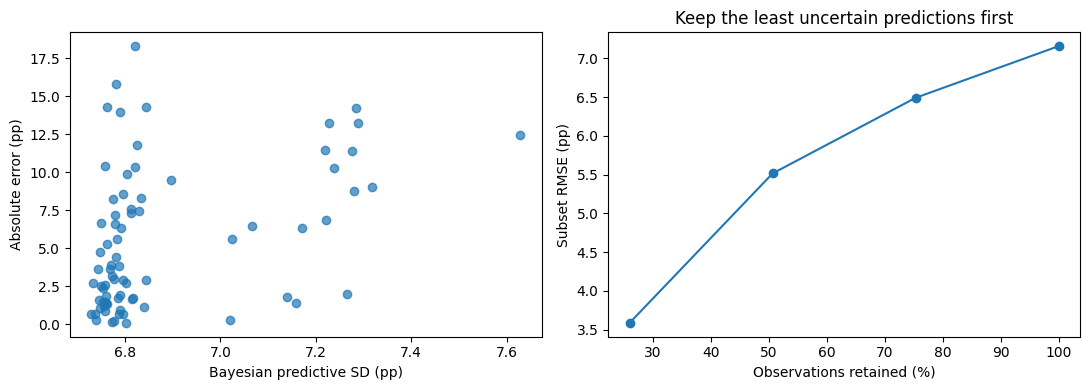

In [13]:
nv_mean,nv_u=model.named_steps['bayesianridge'].predict(model.named_steps['standardscaler'].transform(X_test),return_std=True)
nv_uncertainty_name='Bayesian predictive SD (pp)'
nv_u=np.asarray(nv_u,dtype=float).ravel()
assert nv_u.shape==nv_y.shape and np.isfinite(nv_u).all()
nv_abs=np.abs(nv_predictions[nv_primary]-nv_y)
nv_rho=pd.Series(nv_u).rank().corr(pd.Series(nv_abs).rank()) if np.ptp(nv_u)>0 and np.ptp(nv_abs)>0 else np.nan
nv_urows=[];nv_uorder=np.argsort(nv_u,kind='stable')
for nv_fraction in [.25,.5,.75,1.]:
 nv_ix=nv_uorder[:max(1,int(np.ceil(nv_fraction*len(nv_y))))]
 nv_urows.append({'Coverage (%)':100*len(nv_ix)/len(nv_y),**nv_errors(nv_y[nv_ix],nv_predictions[nv_primary][nv_ix])})
nv_utable=pd.DataFrame(nv_urows)
nv_utable.to_csv(nv_dir/'uncertainty_risk_coverage.csv',index=False)
pd.DataFrame({'Score':nv_u,'Absolute error (pp)':nv_abs}).to_csv(nv_dir/'uncertainty_per_observation.csv',index=False)
print('Uncertainty definition:',nv_uncertainty_name)
print('Spearman uncertainty–absolute-error association:',round(nv_rho,3))
display(nv_utable.round(3))
nv_fig,nv_axes=plt.subplots(1,2,figsize=(11,4))
nv_axes[0].scatter(nv_u,nv_abs,alpha=.7);nv_axes[0].set(xlabel=nv_uncertainty_name,ylabel='Absolute error (pp)')
nv_axes[1].plot(nv_utable['Coverage (%)'],nv_utable['RMSE (pp)'],'o-')
nv_axes[1].set(xlabel='Observations retained (%)',ylabel='Subset RMSE (pp)',title='Keep the least uncertain predictions first')
nv_plot(nv_fig,'uncertainty_error_association')


## 13. Do engineered features help on unseen studies, PFAS and membranes?



Completed transfer tests: ref_ID
Completed transfer tests: PFAS
Completed transfer tests: Membrane


,Holdout,Representation,Prediction,n,RMSE (pp),MAE (pp),Bias (pp)
0,Membrane,Engineered sixteen inputs,Raw,457,8.970,6.727,-1.283
1,Membrane,Engineered sixteen inputs,Clipped 0–100,457,8.781,6.338,-1.672
2,Membrane,Original eight inputs,Raw,457,8.929,6.822,-1.650
3,Membrane,Original eight inputs,Clipped 0–100,457,8.826,6.580,-1.892
4,PFAS,Engineered sixteen inputs,Raw,457,8.873,6.600,-0.990
5,PFAS,Engineered sixteen inputs,Clipped 0–100,457,8.719,6.290,-1.300
6,PFAS,Original eight inputs,Raw,457,8.616,6.248,-1.394
7,PFAS,Original eight inputs,Clipped 0–100,457,8.553,6.102,-1.540
8,ref_ID,Engineered sixteen inputs,Raw,457,8.834,6.487,-0.451
9,ref_ID,Engineered sixteen inputs,Clipped 0–100,457,8.703,6.212,-0.726


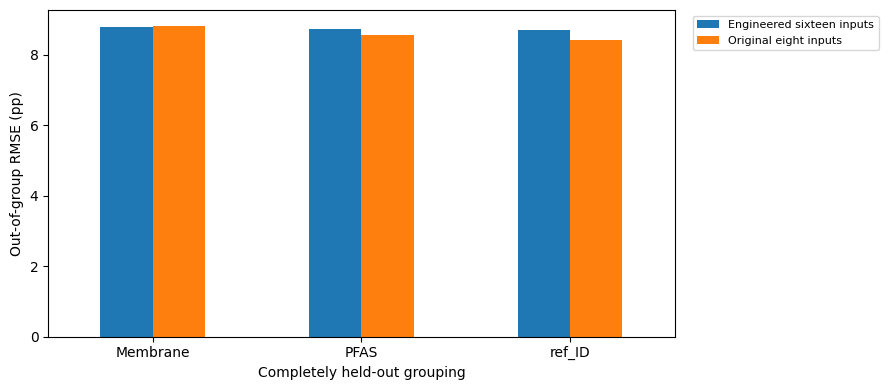

In [14]:
from sklearn.model_selection import LeaveOneGroupOut as NVLeaveGroup
from sklearn.pipeline import make_pipeline as nv_pipeline
from sklearn.linear_model import BayesianRidge as NVRidge
nv_core=['MWCO','CA','Size','log Kow','Init_conc','Pres','IS','charge_product']
nv_feature_sets={'Original eight inputs':nv_core,'Engineered sixteen inputs':list(features)}
nv_transfer_rows=[];nv_transfer_predictions=[]
for nv_field in ['ref_ID','PFAS','Membrane']:
 nv_labels=nv_train[nv_field].astype(str).to_numpy()
 if len(np.unique(nv_labels))<2:continue
 for nv_a,nv_b in NVLeaveGroup().split(nv_train,groups=nv_labels):
  assert set(nv_labels[nv_a]).isdisjoint(set(nv_labels[nv_b]))
  for nv_rep,nv_cols in nv_feature_sets.items():
   nv_model=nv_pipeline(NVScaler(),NVRidge(alpha_1=1e-6,alpha_2=1e-6,lambda_1=1e-6,lambda_2=1e-6))
   nv_model.fit(nv_train.iloc[nv_a][nv_cols],nv_train.iloc[nv_a].Removal_rate)
   nv_raw=nv_model.predict(nv_train.iloc[nv_b][nv_cols]);nv_clip=np.clip(nv_raw,0,100)
   nv_actual=nv_train.iloc[nv_b].Removal_rate.to_numpy()
   for nv_kind,nv_p in [('Raw',nv_raw),('Clipped 0–100',nv_clip)]:
    nv_transfer_rows.append({'Holdout':nv_field,'Held-out group':nv_labels[nv_b[0]],
     'Representation':nv_rep,'Prediction':nv_kind,**nv_errors(nv_actual,nv_p)})
   for nv_i,nv_t,nv_r,nv_c in zip(nv_b,nv_actual,nv_raw,nv_clip):
    nv_transfer_predictions.append({'Holdout':nv_field,'Row':int(nv_i),'Group':nv_labels[nv_i],
     'Representation':nv_rep,'Measured':nv_t,'Raw':nv_r,'Clipped 0–100':nv_c})
 print('Completed transfer tests:',nv_field,flush=True)
nv_transfer=pd.DataFrame(nv_transfer_rows);nv_tp=pd.DataFrame(nv_transfer_predictions)
nv_pool=[]
for (nv_field,nv_rep),nv_g in nv_tp.groupby(['Holdout','Representation']):
 assert len(nv_g)==len(nv_train) and nv_g.Row.nunique()==len(nv_train)
 for nv_kind in ['Raw','Clipped 0–100']:
  nv_pool.append({'Holdout':nv_field,'Representation':nv_rep,'Prediction':nv_kind,
   **nv_errors(nv_g.Measured.to_numpy(),nv_g[nv_kind].to_numpy())})
nv_pool=pd.DataFrame(nv_pool)
for nv_name,nv_table in [('transfer_group_scores',nv_transfer),('transfer_predictions',nv_tp),('transfer_summary',nv_pool)]:
 nv_table.to_csv(nv_dir/f'{nv_name}.csv',index=False)
display(nv_pool.round(3))
nv_bar=nv_pool[nv_pool.Prediction=='Clipped 0–100'].pivot(index='Holdout',columns='Representation',values='RMSE (pp)')
nv_ax=nv_bar.plot.bar(figsize=(9,4),rot=0);nv_ax.set(ylabel='Out-of-group RMSE (pp)',xlabel='Completely held-out grouping')
nv_ax.legend(loc='upper left',bbox_to_anchor=(1.02,1),fontsize=8)
nv_plot(nv_ax.figure,'feature_representation_transfer')


## 14. Exports and research contribution



In [15]:
nv_key_cols=['ref_ID','PFAS','Membrane','MWCO','CA','Size','log Kow','Init_conc','Pres','IS','charge_product','Mw','pH','pKa','IEP']
def nv_row_key(row):
 vals=[]
 for key in nv_key_cols:
  value=row[key]
  vals.append(str(value) if key in ['PFAS','Membrane'] else format(float(value),'.10g'))
 return nv_hashlib.sha256(nv_json.dumps(vals,separators=(',',':')).encode()).hexdigest()
nv_export=nv_audit.copy();nv_export['Fingerprint']=nv_test.apply(nv_row_key,axis=1)
nv_export['Duplicate']=nv_export.groupby('Fingerprint').cumcount()
nv_export['Row key']=nv_export.Fingerprint+'-'+nv_export.Duplicate.astype(str)
nv_export['Measured (%)']=nv_y
for nv_name,nv_pred in nv_predictions.items():nv_export[nv_name]=nv_pred
nv_export.to_csv(nv_dir/'predictions_for_cross_notebook_comparison.csv',index=False)
nv_settings={'primary_model':nv_primary,'distance_features':list(nv_physical(nv_train).columns),
 'training_distance_95th_percentile':nv_threshold,'size_training_median':nv_ratio_cut,
 'absolute_charge_training_median':nv_charge_cut,'distance_neighbours':5,
 'uncertainty_definition':nv_uncertainty_name,'uncertainty_error_spearman':None if pd.isna(nv_rho) else float(nv_rho),
 'minimum_group_count_flag':nv_min_n,'external_test_previously_inspected':True,
 'training_rows':len(nv_train),'test_rows':len(nv_test),
 'unchanged_original_sections':list(range(1,10)),'new_sections':list(range(10,15))}
(nv_dir/'analysis_settings.json').write_text(nv_json.dumps(nv_settings,indent=2))
nv_archive=nv_shutil.make_archive(str(nv_dir.resolve()),'zip',root_dir=nv_dir)
print('Additional figures, tables, row-aligned predictions and settings:',nv_archive)


Additional figures, tables, row-aligned predictions and settings: /content/ridge_novelty_results.zip
